# Dataset Exploration: Dataset Exploration and Call Length Analytics

This notebook performs comprehensive exploratory data analysis across both the positive target class (Philippine Eagle) and the sympatric hard-negatives corpus:

1. **Philippine Eagle Dataset (`data/raw/eagle-audios/`)**:
   - Verifies pairing between raw audio files in `audios/` and verified Raven selection tables in `selectionTables/`.
   - Inspects audio recording properties (duration, sample rate, channels).
   - Filters out rows marked as `Unnecessary` (handling annotator spelling variants) and isolates confirmed eagle calls (`PhilEagle_short`, `PhilEagle_long`).
   - Computes analytics for call durations (mean, median, min, max, percentiles).
   - Generates visualizations of call lengths, subtypes, and frequency bands.

2. **Hard Negatives Dataset (`data/raw/hard-negatives/`)**:
   - Loads and cleans eBird / Macaulay Library catalog metadata from `raw-metadata.csv`.
   - Verifies 1-to-1 pairing of all 707 multi-format audio files (`.wav`, `.mp3`, `.m4a`) in `audios/`.
   - Inspects audio properties, durations, sample rates, and format distribution.
   - Explores species diversity across sympatric raptors and forest birds (e.g., Crested Goshawk, Brahminy Kite, Hawk-Eagles).
   - Analyzes geographic recording distribution across Philippine provinces.

3. **Cross-Corpus Comparative Analysis**:
   - Compares total recordings, total audio duration (hours), and class representation between eagle audio and hard-negatives.
   - Saves all publication-grade figures to `outputs/figures/` prefixed with `dataset-exploration-`.


## 1. Imports and Configuration


In [1]:
import os
import re
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf
import audioread

warnings.filterwarnings("ignore")

# Random seed
SEED = 42
np.random.seed(SEED)

NOTEBOOK_ID = "dataset-exploration"

# Paths
CURRENT_PATH = Path.cwd()
def find_project_root():
    p = Path.cwd().resolve()
    while p != p.parent:
        if (p / "data").exists() and (p / "AGENTS.md").exists():
            return p
        p = p.parent
    return Path.cwd().resolve().parent.parent

PROJECT_ROOT = find_project_root()
EXPERIMENT_DIR = Path.cwd().resolve()
OUTPUTS_DIR = EXPERIMENT_DIR / "outputs"

RAW_DIR = PROJECT_ROOT / "data" / "raw"

# Eagle audios directory paths
EAGLE_RAW_DIR = RAW_DIR / "eagle-audios"
AUDIO_DIR = EAGLE_RAW_DIR / "audios"
TABLES_DIR = EAGLE_RAW_DIR / "selectionTables"
EAGLE_META_PATH = EAGLE_RAW_DIR / "raw-metadata.csv"

# Hard negatives directory paths
HARD_NEG_RAW_DIR = RAW_DIR / "hard-negatives"
HARD_NEG_AUDIO_DIR = HARD_NEG_RAW_DIR / "audios"
HARD_NEG_META_PATH = HARD_NEG_RAW_DIR / "raw-metadata.csv"

FIGURES_DIR = OUTPUTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Plotting style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.dpi"] = 150

print(f"Project root:              {PROJECT_ROOT}")
print(f"Eagle audio directory:     {AUDIO_DIR}")
print(f"Eagle tables directory:    {TABLES_DIR}")
print(f"Hard negatives audio dir:  {HARD_NEG_AUDIO_DIR}")
print(f"Hard negatives meta path:  {HARD_NEG_META_PATH}")
print(f"Figures output:            {FIGURES_DIR}")


Project root:              /home/fumei/Documents/MachineLearning/EagleSoundClassification
Eagle audio directory:     /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/raw/eagle-audios/audios
Eagle tables directory:    /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/raw/eagle-audios/selectionTables
Hard negatives audio dir:  /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/raw/hard-negatives/audios
Hard negatives meta path:  /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/raw/hard-negatives/raw-metadata.csv
Figures output:            /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/01-dataset-exploration/outputs/figures


## 2. Audio and Selection Table Pairing Verification


In [2]:
# Scan raw audio files and selection tables
audio_files = sorted(AUDIO_DIR.glob("*.wav"))
table_files = sorted(TABLES_DIR.glob("*.txt"))

audio_stems = {f.stem: f for f in audio_files}
table_stems = {f.stem: f for f in table_files}

# Check matching between stems
paired_stems = sorted(list(set(audio_stems.keys()) & set(table_stems.keys())))
audios_without_table = sorted(list(set(audio_stems.keys()) - set(table_stems.keys())))
tables_without_audio = sorted(list(set(table_stems.keys()) - set(audio_stems.keys())))

print("=" * 60)
print("DATASET INVENTORY & PAIRING")
print("=" * 60)
print(f"Total audio files (.wav):            {len(audio_files)}")
print(f"Total selection tables (.txt):       {len(table_files)}")
print(f"Direct matches:                      {len(paired_stems)}")
print(f"Audios missing selection tables:     {len(audios_without_table)}")
for stem in audios_without_table:
    print(f"  - {stem}.wav")
print(f"Selection tables missing audio:      {len(tables_without_audio)}")
for stem in tables_without_audio:
    print(f"  - {stem}.txt")

# Check known duplicates or naming differences
if "converted_135598" in audios_without_table and "converted_converted_135598" in paired_stems:
    print("\nNote: converted_135598.wav is an exact byte duplicate of converted_converted_135598.wav, which pairs with converted_converted_135598.txt.")
print("=" * 60)

# Build pairing summary table
pairing_data = []
for f in audio_files:
    stem = f.stem
    has_table = stem in table_stems
    table_name = table_stems[stem].name if has_table else "None"
    status = "Paired" if has_table else ("Duplicate of converted_converted_135598" if stem == "converted_135598" else "Missing Table")
    pairing_data.append({
        "AudioFile": f.name,
        "AudioStem": stem,
        "HasSelectionTable": has_table,
        "SelectionTableFile": table_name,
        "Status": status
    })

df_pairing = pd.DataFrame(pairing_data)
df_pairing["Status"].value_counts().to_frame()


DATASET INVENTORY & PAIRING
Total audio files (.wav):            59
Total selection tables (.txt):       59
Direct matches:                      59
Audios missing selection tables:     0
Selection tables missing audio:      0


,count
Status,
Paired,59


## 3. Visualize Audio Pairing Status


Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/01-dataset-exploration/outputs/figures/file-pairing-coverage.png


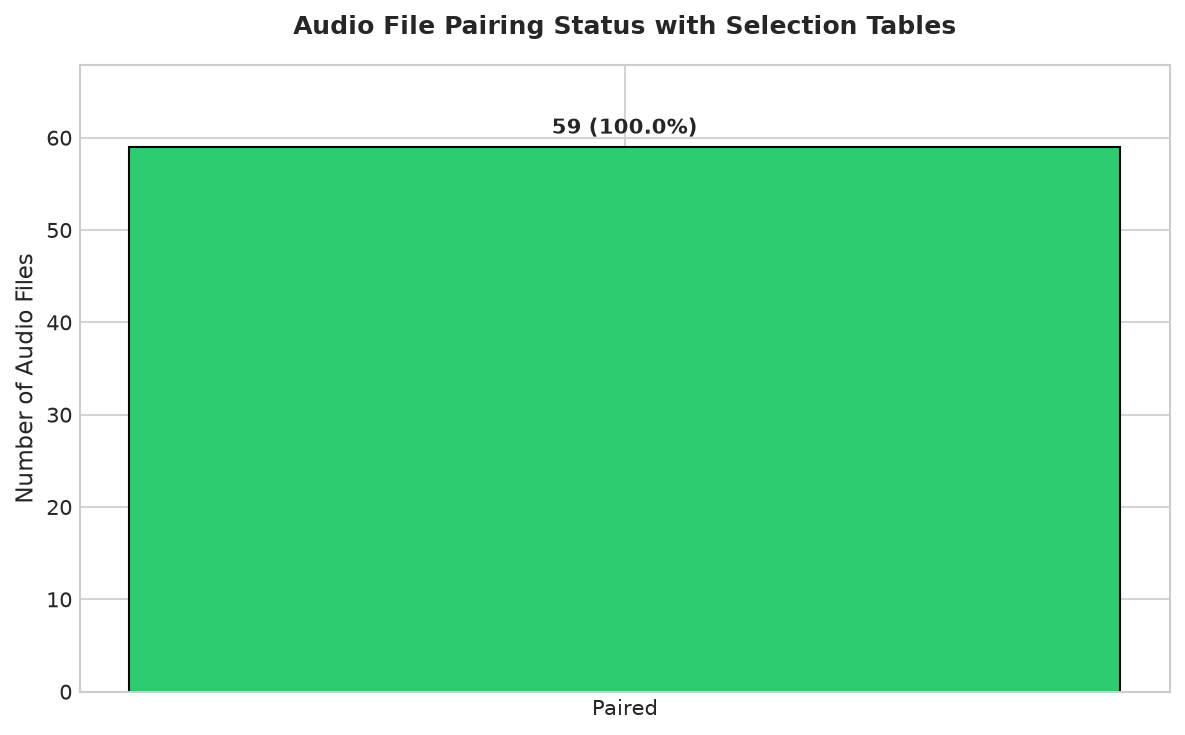

In [3]:
# Plot audio pairing status
status_counts = df_pairing["Status"].value_counts()
colors = ["#2ecc71", "#e74c3c", "#f39c12"]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(status_counts.index, status_counts.values, color=colors[:len(status_counts)], width=0.5, edgecolor="black")

for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height} ({height/len(df_pairing)*100:.1f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontweight="bold")

ax.set_title("Audio File Pairing Status with Selection Tables", pad=15, fontweight="bold")
ax.set_ylabel("Number of Audio Files")
ax.set_ylim(0, max(status_counts.values) * 1.15)
plt.tight_layout()

# Save figure
output_path = FIGURES_DIR / "file-pairing-coverage.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
print(f"Saved figure: {output_path}")
plt.show()


## 4. Inspect Audio Recording Properties and Durations


In [4]:
# Read audio file metadata
audio_meta = []
for f in audio_files:
    info = sf.info(f)
    audio_meta.append({
        "AudioFile": f.name,
        "AudioStem": f.stem,
        "Duration_s": info.duration,
        "Duration_min": info.duration / 60.0,
        "SampleRate_Hz": info.samplerate,
        "Channels": info.channels,
        "Format": info.format,
        "Subtype": info.subtype
    })

df_audio_props = pd.DataFrame(audio_meta)
total_audio_sec = df_audio_props["Duration_s"].sum()
total_audio_hrs = total_audio_sec / 3600.0

print("=" * 60)
print("AUDIO RECORDINGS SUMMARY")
print("=" * 60)
print(f"Total audio files:         {len(df_audio_props)}")
print(f"Total duration:            {total_audio_sec:.2f} seconds ({total_audio_hrs:.2f} hours)")
print(f"Mean duration:             {df_audio_props['Duration_s'].mean():.2f} seconds ({df_audio_props['Duration_s'].mean()/60:.2f} min)")
print(f"Min duration:              {df_audio_props['Duration_s'].min():.2f} seconds ({df_audio_props['Duration_s'].min()/60:.2f} min)")
print(f"Max duration:              {df_audio_props['Duration_s'].max():.2f} seconds ({df_audio_props['Duration_s'].max()/60:.2f} min)")
print(f"Median duration:           {df_audio_props['Duration_s'].median():.2f} seconds ({df_audio_props['Duration_s'].median()/60:.2f} min)")
print(f"Sample rates:              {df_audio_props['SampleRate_Hz'].unique().tolist()} Hz")
print(f"Channel counts:            {df_audio_props['Channels'].unique().tolist()} channel(s)")
print("=" * 60)

df_audio_props[["Duration_s", "Duration_min"]].describe()


AUDIO RECORDINGS SUMMARY
Total audio files:         59
Total duration:            14605.97 seconds (4.06 hours)
Mean duration:             247.56 seconds (4.13 min)
Min duration:              4.94 seconds (0.08 min)
Max duration:              2528.68 seconds (42.14 min)
Median duration:           132.57 seconds (2.21 min)
Sample rates:              [44100] Hz
Channel counts:            [1] channel(s)


,Duration_s,Duration_min
count,59.000000,59.000000
mean,247.558768,4.125979
std,397.189651,6.619828
min,4.937143,0.082286
25%,37.991179,0.633186
50%,132.572880,2.209548
75%,321.977902,5.366298
max,2528.683379,42.144723


## 5. Load and Consolidate Selection Tables


In [5]:
# Load all selection tables into a single DataFrame
table_dfs = []
for f in table_files:
    df_item = pd.read_csv(f, sep="\t")
    df_item.columns = [col.strip() for col in df_item.columns]
    df_item["TableFile"] = f.name
    df_item["AudioStem"] = f.stem
    table_dfs.append(df_item)

df_all_annotations = pd.concat(table_dfs, ignore_index=True)
df_all_annotations["Duration (s)"] = df_all_annotations["End Time (s)"] - df_all_annotations["Begin Time (s)"]

print(f"Loaded {len(table_files)} selection tables.")
print(f"Total annotations: {len(df_all_annotations)}")
df_all_annotations.head(5)


Loaded 59 selection tables.
Total annotations: 4066


,Selection,View,Channel,Begin Time (s),End Time (s),Low Freq (Hz),High Freq (Hz),Peak Freq (Hz),BW 90% (Hz),Type,Quality,TableFile,AudioStem,Duration (s)
0,1,Spectrogram 1,1,0.000000,4.226919,0.000,18850.315,172.266,861.328,Unnecessary,NaN,converted_135598.txt,converted_135598,4.226919
1,2,Spectrogram 1,1,6.209091,7.028494,2065.574,2995.082,2239.453,689.062,PhilEagle_long,Low,converted_135598.txt,converted_135598,0.819403
2,3,Spectrogram 1,1,8.027765,8.832179,2117.213,2685.246,2411.719,344.531,PhilEagle_long,Medium,converted_135598.txt,converted_135598,0.804414
3,4,Spectrogram 1,1,11.578794,12.198342,2168.852,2685.246,2670.117,258.398,PhilEagle_long,Low,converted_135598.txt,converted_135598,0.619548
4,5,Spectrogram 1,1,13.387476,13.977046,2117.213,2685.246,2411.719,430.664,PhilEagle_long,Low,converted_135598.txt,converted_135598,0.589570


## 6. Filter Out Unnecessary Annotations


In [6]:
# View raw annotation types
raw_type_counts = df_all_annotations["Type"].value_counts(dropna=False)
print("Raw annotation types:")
print(raw_type_counts)

# Filter out all variations of unnecessary (including typos like Unnecessaryq, Unecessary, Unnecessasry)
unnecessary_regex = r"un+ec+es+"
unnecessary_mask = df_all_annotations["Type"].str.contains(unnecessary_regex, case=False, na=False)

disregarded_count = unnecessary_mask.sum()
disregarded_types = df_all_annotations.loc[unnecessary_mask, "Type"].value_counts().to_dict()

print("\n" + "=" * 60)
print(f"Disregarded {disregarded_count} unnecessary rows:")
for t, cnt in disregarded_types.items():
    print(f"  - '{t}': {cnt}")
print("=" * 60)

# Keep only relevant call rows
df_filtered = df_all_annotations[~unnecessary_mask].copy()

# Fix minor typo (PhilEagle_longt -> PhilEagle_long)
df_filtered["CleanType"] = df_filtered["Type"].replace({"PhilEagle_longt": "PhilEagle_long"})

# Create eagle call and ambiguous flags
df_filtered["IsEagleCall"] = df_filtered["CleanType"].str.startswith("PhilEagle", na=False)
df_filtered["IsAmbiguous"] = df_filtered["CleanType"] == "Ambiguous"

print("\nFiltered annotation distribution:")
print(df_filtered["CleanType"].value_counts())
print(f"\nTotal Confirmed Eagle Calls: {df_filtered['IsEagleCall'].sum()}")
print(f"Total Ambiguous Calls:         {df_filtered['IsAmbiguous'].sum()}")


Raw annotation types:
Type
PhilEagle_short    2744
PhilEagle_long     1079
Unnecessary         148
Ambiguous            87
Unnecessaryq          2
Unecessary            2
Unnecessasry          2
PhilEagle_longt       2
Name: count, dtype: int64

Disregarded 154 unnecessary rows:
  - 'Unnecessary': 148
  - 'Unnecessaryq': 2
  - 'Unecessary': 2
  - 'Unnecessasry': 2

Filtered annotation distribution:
CleanType
PhilEagle_short    2744
PhilEagle_long     1081
Ambiguous            87
Name: count, dtype: int64

Total Confirmed Eagle Calls: 3825
Total Ambiguous Calls:         87


## 7. Calculate Eagle Call Length Analytics


In [7]:
# Analyze duration of confirmed eagle calls
df_eagle = df_filtered[df_filtered["IsEagleCall"]].copy()

def compute_stats(series: pd.Series) -> dict:
    return {
        "Count": int(len(series)),
        "Mean (s)": float(series.mean()),
        "Std Dev (s)": float(series.std()),
        "Min (s)": float(series.min()),
        "25% (Q1) (s)": float(series.quantile(0.25)),
        "Median (s)": float(series.median()),
        "75% (Q3) (s)": float(series.quantile(0.75)),
        "95% (s)": float(series.quantile(0.95)),
        "Max (s)": float(series.max()),
        "IQR (s)": float(series.quantile(0.75) - series.quantile(0.25))
    }

stats_dict = {
    "All Eagle Calls": compute_stats(df_eagle["Duration (s)"])
}

for call_type in sorted(df_eagle["CleanType"].unique()):
    subset = df_eagle[df_eagle["CleanType"] == call_type]["Duration (s)"]
    stats_dict[call_type] = compute_stats(subset)

df_ambiguous = df_filtered[df_filtered["IsAmbiguous"]]
if len(df_ambiguous) > 0:
    stats_dict["Ambiguous"] = compute_stats(df_ambiguous["Duration (s)"])

df_analytics = pd.DataFrame(stats_dict).T

print("=" * 80)
print("EAGLE CALL DURATION ANALYTICS (IN SECONDS)")
print("=" * 80)
print(df_analytics.round(4).to_string())
print("=" * 80)

mean_len = df_eagle["Duration (s)"].mean()
min_len = df_eagle["Duration (s)"].min()
max_len = df_eagle["Duration (s)"].max()
median_len = df_eagle["Duration (s)"].median()

print(f"\nKey Duration Statistics:")
print(f"  * Average (Mean): {mean_len:.4f} seconds ({mean_len*1000:.1f} ms)")
print(f"  * Minimum:        {min_len:.4f} seconds ({min_len*1000:.1f} ms)")
print(f"  * Maximum:        {max_len:.4f} seconds ({max_len*1000:.1f} ms)")
print(f"  * Median:         {median_len:.4f} seconds ({median_len*1000:.1f} ms)")


EAGLE CALL DURATION ANALYTICS (IN SECONDS)
                  Count  Mean (s)  Std Dev (s)  Min (s)  25% (Q1) (s)  Median (s)  75% (Q3) (s)  95% (s)  Max (s)  IQR (s)
All Eagle Calls  3825.0    0.7346       0.2872   0.1250        0.5447      0.7043        0.9001   1.2538   2.2634   0.3554
PhilEagle_long   1081.0    0.8696       0.2945   0.2273        0.6530      0.7894        1.0392   1.4555   2.2634   0.3863
PhilEagle_short  2744.0    0.6814       0.2661   0.1250        0.4929      0.6629        0.8447   1.1686   1.5415   0.3518
Ambiguous          87.0    0.8331       0.3973   0.1849        0.5146      0.7944        1.0417   1.5208   2.0185   0.5271

Key Duration Statistics:
  * Average (Mean): 0.7346 seconds (734.6 ms)
  * Minimum:        0.1250 seconds (125.0 ms)
  * Maximum:        2.2634 seconds (2263.4 ms)
  * Median:         0.7043 seconds (704.3 ms)


## 8. Visualize Eagle Call Duration Distribution


Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/01-dataset-exploration/outputs/figures/eagle-call-duration-distribution.png


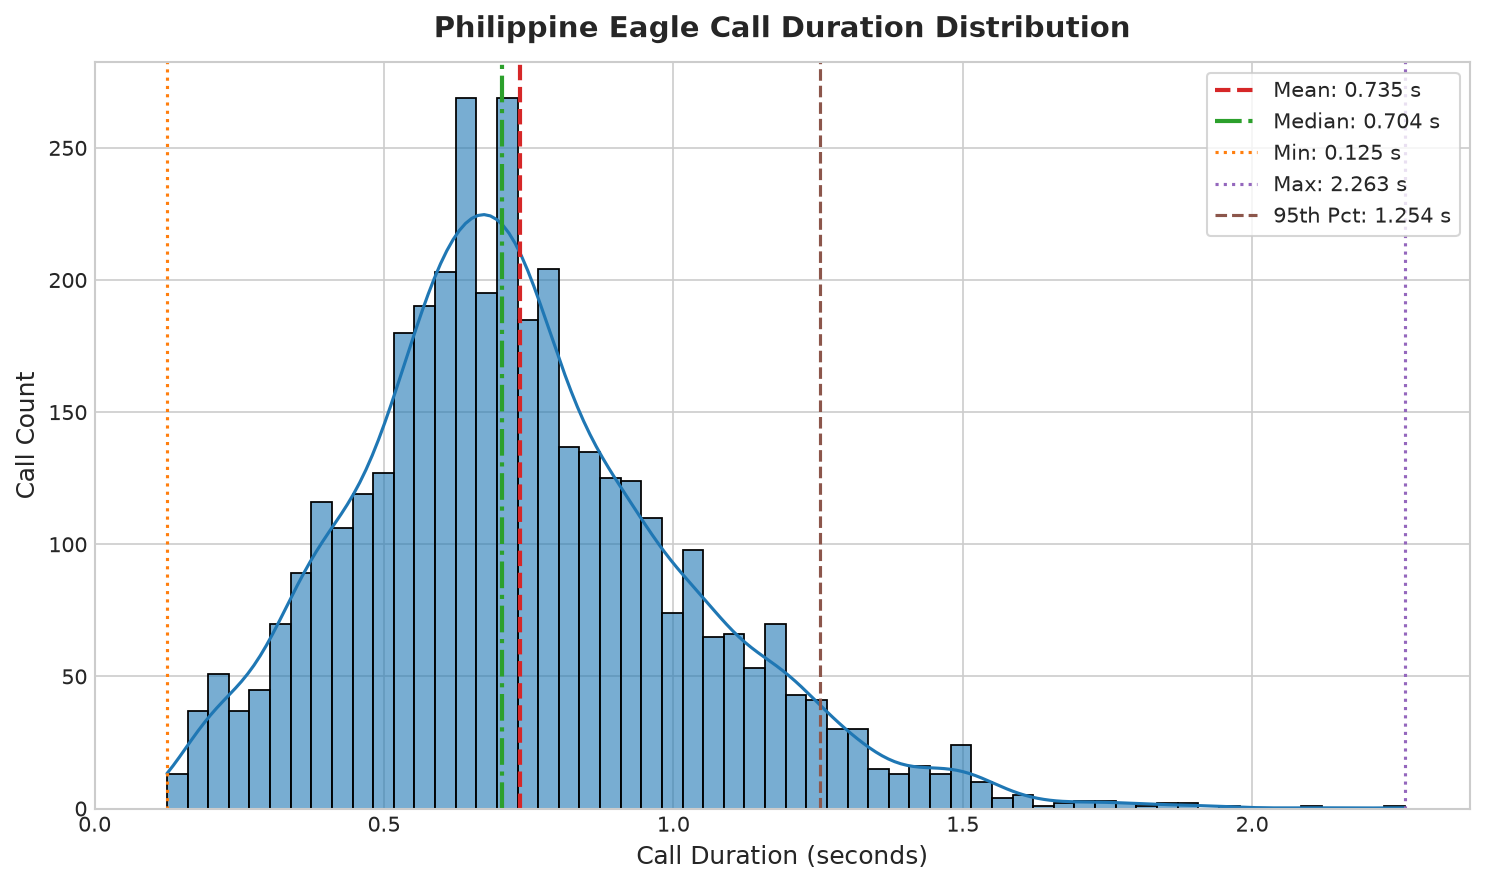

In [8]:
# Plot histogram and KDE of eagle call durations
durations = df_eagle["Duration (s)"]

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(durations, kde=True, bins=60, color="#1f77b4", edgecolor="black", alpha=0.6, ax=ax)

# Reference lines
ax.axvline(mean_len, color="#d62728", linestyle="--", linewidth=2, label=f"Mean: {mean_len:.3f} s")
ax.axvline(median_len, color="#2ca02c", linestyle="-.", linewidth=2, label=f"Median: {median_len:.3f} s")
ax.axvline(min_len, color="#ff7f0e", linestyle=":", linewidth=1.5, label=f"Min: {min_len:.3f} s")
ax.axvline(max_len, color="#9467bd", linestyle=":", linewidth=1.5, label=f"Max: {max_len:.3f} s")

p95 = durations.quantile(0.95)
ax.axvline(p95, color="#8c564b", linestyle="--", linewidth=1.5, label=f"95th Pct: {p95:.3f} s")

ax.set_title("Philippine Eagle Call Duration Distribution", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Call Duration (seconds)", fontsize=12)
ax.set_ylabel("Call Count", fontsize=12)
ax.legend(loc="upper right", frameon=True, fontsize=10)
ax.set_xlim(0, max_len * 1.05)

plt.tight_layout()

# Save figure
fig_path = FIGURES_DIR / "eagle-call-duration-distribution.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"Saved figure: {fig_path}")
plt.show()


## 9. Visualize Call Duration by Subtype and Quality


Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/01-dataset-exploration/outputs/figures/call-duration-by-subtype.png


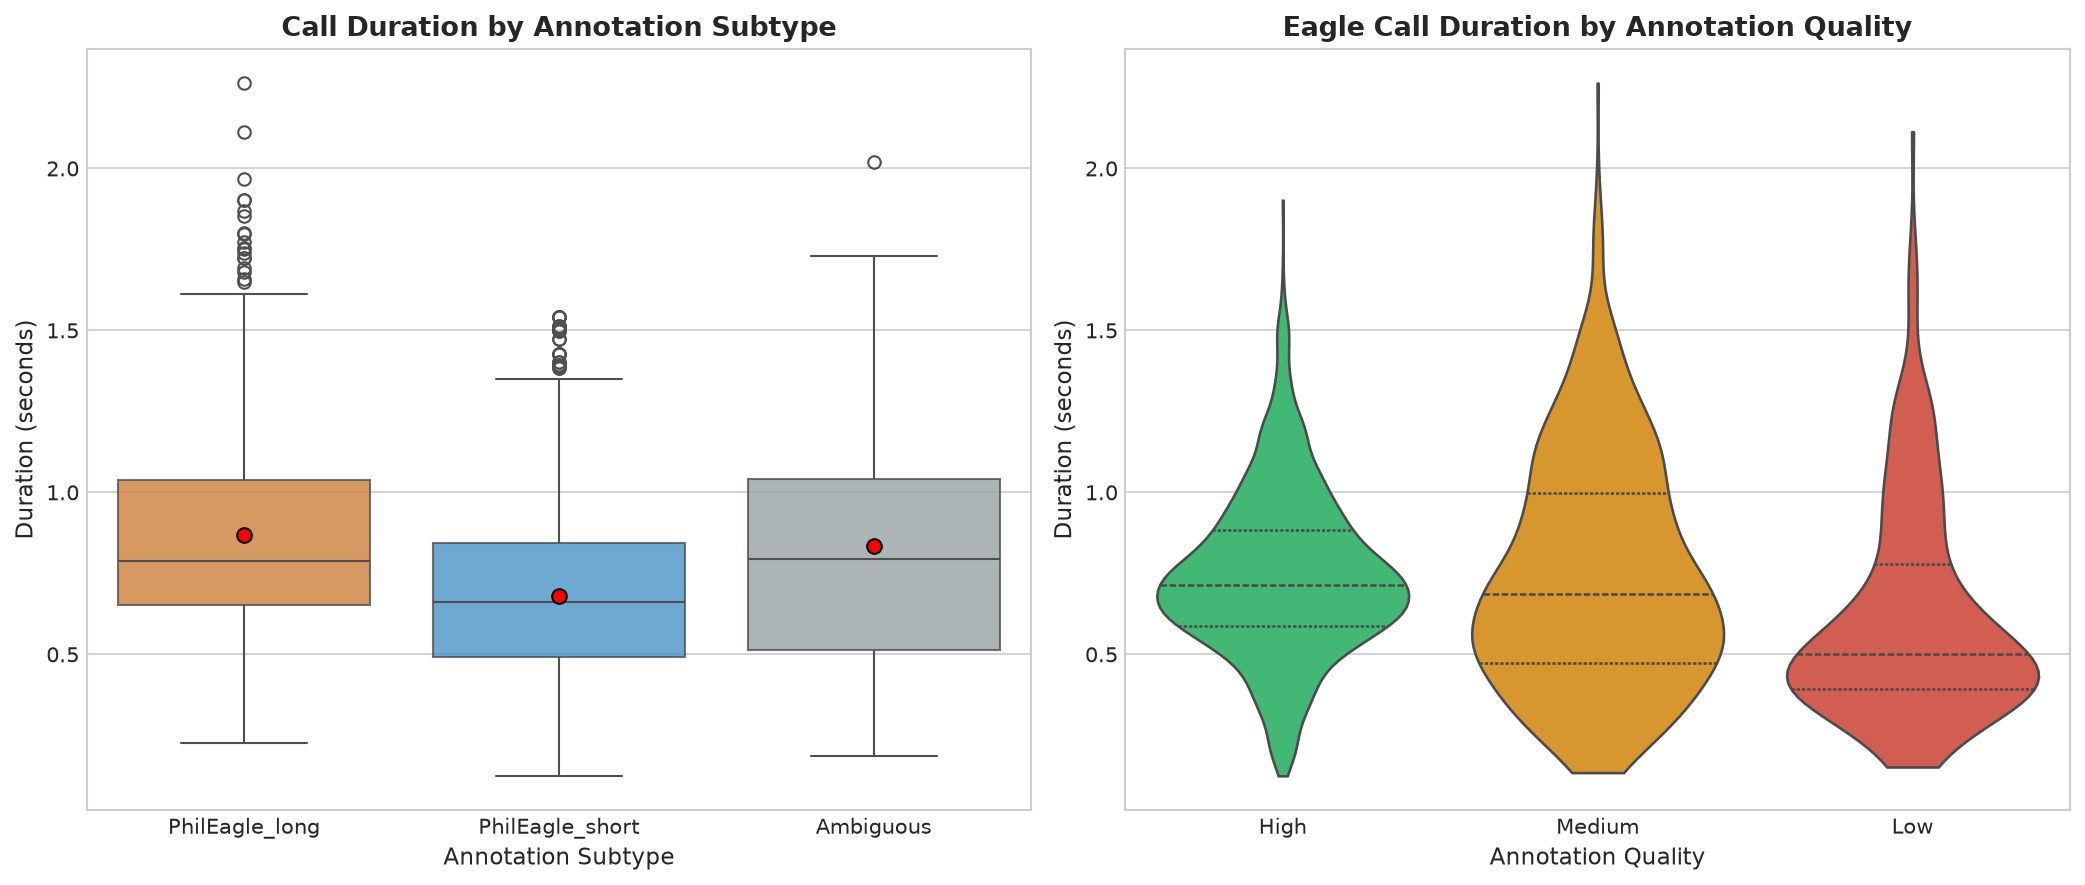

In [9]:
# Compare call duration across subtype and quality
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Panel 1: Duration by subtype
type_palette = {"PhilEagle_short": "#3498db", "PhilEagle_long": "#e67e22", "Ambiguous": "#95a5a6"}
sns.boxplot(
    data=df_filtered,
    x="CleanType",
    y="Duration (s)",
    palette=type_palette,
    ax=axes[0],
    boxprops=dict(alpha=0.8),
    showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "red", "markeredgecolor": "black", "markersize": 7}
)
axes[0].set_title("Call Duration by Annotation Subtype", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Annotation Subtype", fontsize=11)
axes[0].set_ylabel("Duration (seconds)", fontsize=11)

# Panel 2: Duration by quality for eagle calls
quality_order = ["High", "Medium", "Low"]
valid_quality_df = df_eagle[df_eagle["Quality"].isin(quality_order)]
quality_palette = {"High": "#2ecc71", "Medium": "#f39c12", "Low": "#e74c3c"}

sns.violinplot(
    data=valid_quality_df,
    x="Quality",
    y="Duration (s)",
    order=quality_order,
    palette=quality_palette,
    ax=axes[1],
    inner="quartile",
    cut=0
)
axes[1].set_title("Eagle Call Duration by Annotation Quality", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Annotation Quality", fontsize=11)
axes[1].set_ylabel("Duration (seconds)", fontsize=11)

plt.tight_layout()

# Save figure
fig_path = FIGURES_DIR / "call-duration-by-subtype.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"Saved figure: {fig_path}")
plt.show()


## 10. Visualize Call Frequency and Quality Distribution


Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/01-dataset-exploration/outputs/figures/call-counts-and-quality.png


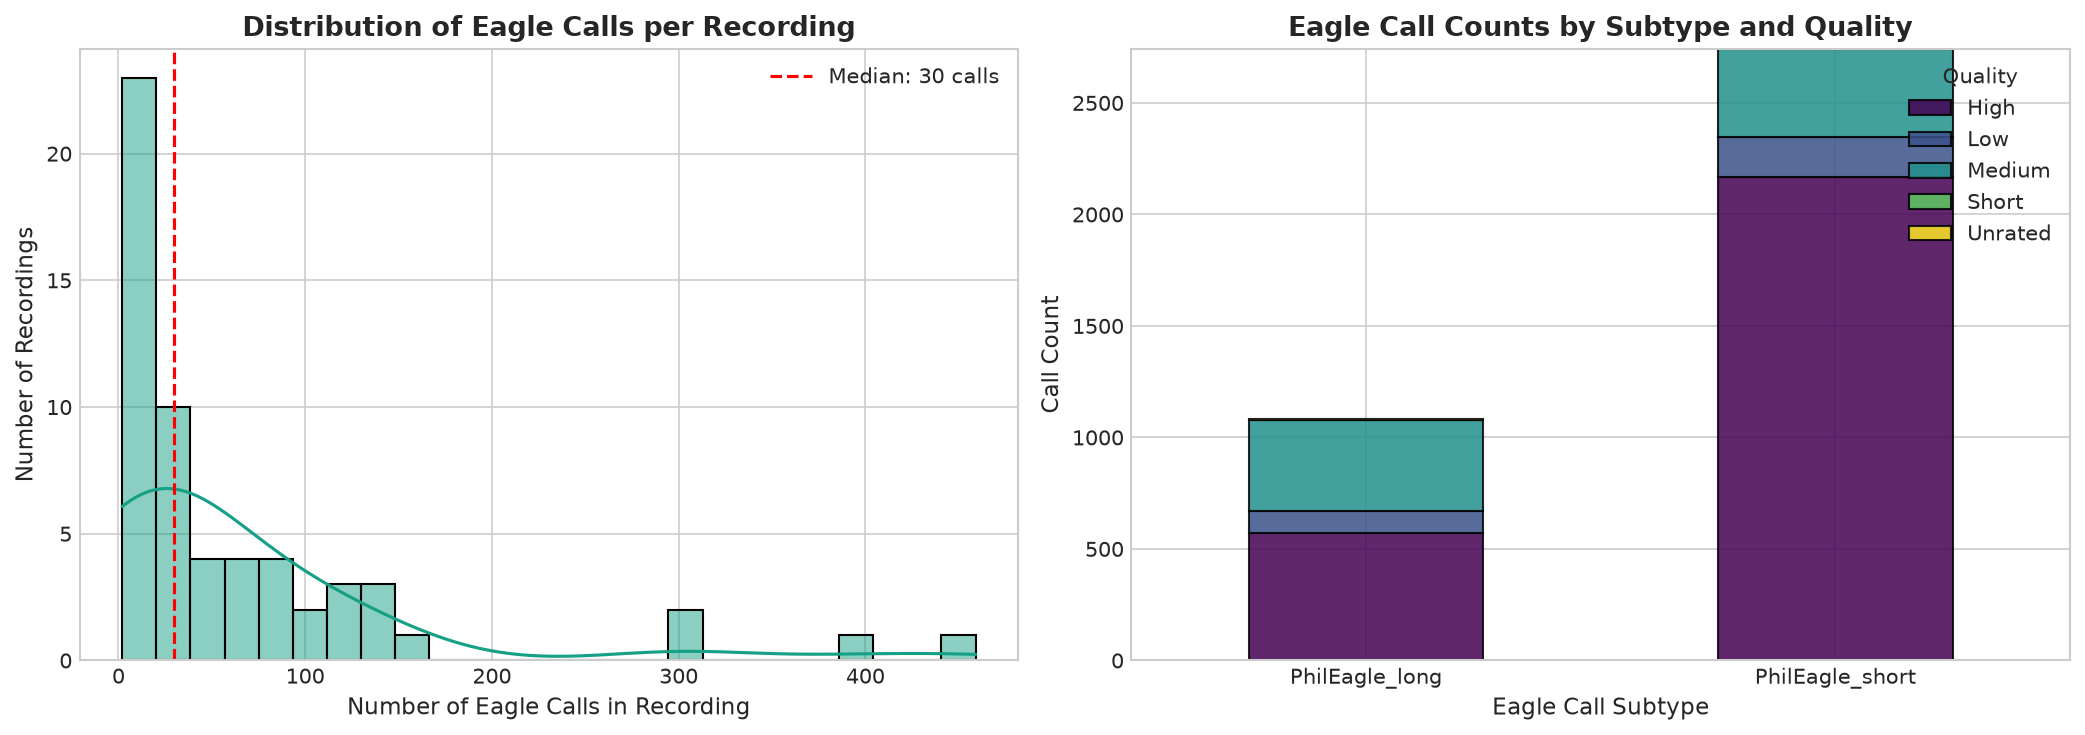

In [10]:
# Plot call frequency per audio file and quality breakdown
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Calls per audio file
calls_per_audio = df_eagle.groupby("AudioStem").size()
sns.histplot(calls_per_audio, bins=25, kde=True, color="#16a085", ax=axes[0], edgecolor="black")
axes[0].set_title("Distribution of Eagle Calls per Recording", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Number of Eagle Calls in Recording", fontsize=11)
axes[0].set_ylabel("Number of Recordings", fontsize=11)
axes[0].axvline(calls_per_audio.median(), color="red", linestyle="--", label=f"Median: {calls_per_audio.median():.0f} calls")
axes[0].legend()

# Panel 2: Eagle call counts by subtype and quality
count_cross = pd.crosstab(df_eagle["CleanType"], df_eagle["Quality"].fillna("Unrated"))
count_cross.plot(kind="bar", stacked=True, colormap="viridis", ax=axes[1], edgecolor="black", alpha=0.85)
axes[1].set_title("Eagle Call Counts by Subtype and Quality", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Eagle Call Subtype", fontsize=11)
axes[1].set_ylabel("Call Count", fontsize=11)
axes[1].legend(title="Quality", loc="upper right")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()

# Save figure
fig_path = FIGURES_DIR / "call-counts-and-quality.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"Saved figure: {fig_path}")
plt.show()


## 11. Load Hard Negatives Catalog Metadata


In [11]:
# Load eBird / Macaulay Library catalog metadata for hard negatives
# Note: The raw metadata CSV begins with 3 comment lines generated by merge-csv.com
df_hard_neg_meta_raw = pd.read_csv(HARD_NEG_META_PATH, skiprows=3)

# Clean first column name (handle UTF-8 BOM if present)
col0 = df_hard_neg_meta_raw.columns[0]
df_hard_neg_meta = df_hard_neg_meta_raw.rename(columns={col0: "catalog_number"}).copy()
df_hard_neg_meta["catalog_number"] = df_hard_neg_meta["catalog_number"].astype(str).str.strip()

print(f"Total hard-negative metadata records loaded: {len(df_hard_neg_meta)}")
print(f"Metadata columns count:                      {len(df_hard_neg_meta.columns)}")
print(f"Unique catalog numbers:                      {df_hard_neg_meta['catalog_number'].nunique()}")
print(f"Distinct common names:                       {df_hard_neg_meta['Common Name'].nunique()}")
print(f"Distinct scientific names:                   {df_hard_neg_meta['Scientific Name'].nunique()}")

# Display sample entries
df_hard_neg_meta[["catalog_number", "Common Name", "Scientific Name", "State", "Date", "Format"]].head(8)


Total hard-negative metadata records loaded: 707
Metadata columns count:                      46
Unique catalog numbers:                      707
Distinct common names:                       9
Distinct scientific names:                   9


,catalog_number,Common Name,Scientific Name,State,Date,Format
0,609063968,Philippine Honey-buzzard,Pernis steerei,Agusan del Sur,2009-11-24,Audio
1,217253,Philippine Honey-buzzard,Pernis steerei,Davao Oriental,2015-06-27,Audio
2,18664,Philippine Honey-buzzard,Pernis steerei,Cotabato,1979-03-08,Audio
3,618938423,Philippine Hawk-Eagle,Nisaetus philippensis,Bataan,2024-05-12,Audio
4,609070587,Philippine Hawk-Eagle,Nisaetus philippensis,Laguna,2006-12-20,Audio
5,246985381,Philippine Hawk-Eagle,Nisaetus philippensis,Rizal,2020-07-01,Audio
6,203997421,Philippine Hawk-Eagle,Nisaetus philippensis,Ilocos Norte,2009-02-01,Audio
7,38604,Philippine Hawk-Eagle,Nisaetus philippensis,Bataan,1981-05-10,Audio


## 12. Verify Hard Negatives Audio and Catalog Pairing


In [12]:
# Scan hard negatives audio directory for all audio files (.wav, .mp3, .m4a)
hard_neg_audio_files = sorted([
    f for f in HARD_NEG_AUDIO_DIR.iterdir()
    if f.suffix.lower() in [".wav", ".mp3", ".m4a"]
])

# Map catalog stem to full audio path
hard_neg_audio_map = {f.stem.strip(): f for f in hard_neg_audio_files}
meta_catalog_set = set(df_hard_neg_meta["catalog_number"])
audio_catalog_set = set(hard_neg_audio_map.keys())

# Pairing statistics
matched_hard_neg = sorted(list(meta_catalog_set & audio_catalog_set))
audio_without_meta = sorted(list(audio_catalog_set - meta_catalog_set))
meta_without_audio = sorted(list(meta_catalog_set - audio_catalog_set))

print(f"Total audio files in hard-negatives/audios/: {len(hard_neg_audio_files)}")
print(f"Total metadata records in catalog:          {len(df_hard_neg_meta)}")
print(f"Successfully matched 1-to-1 pairs:          {len(matched_hard_neg)}")
print(f"Audio files without metadata record:        {len(audio_without_meta)}")
print(f"Metadata records without audio file:        {len(meta_without_audio)}")

assert len(matched_hard_neg) == len(hard_neg_audio_files), "Mismatch detected in hard-negatives pairing!"
print("100% complete pairing confirmed across the entire hard-negatives corpus.")


Total audio files in hard-negatives/audios/: 707
Total metadata records in catalog:          707
Successfully matched 1-to-1 pairs:          707
Audio files without metadata record:        0
Metadata records without audio file:        0
100% complete pairing confirmed across the entire hard-negatives corpus.


## 13. Inspect Hard Negatives Audio Properties and Durations


In [13]:
# Helper function to read audio properties across .wav, .mp3, and .m4a formats
def get_audio_info(file_path):
    try:
        info = sf.info(str(file_path))
        return {
            "duration_sec": info.duration,
            "sample_rate": info.samplerate,
            "channels": info.channels,
            "format": info.format.upper()
        }
    except Exception:
        # Fallback for AAC/M4A containers using audioread
        with audioread.audio_open(str(file_path)) as a:
            return {
                "duration_sec": a.duration,
                "sample_rate": a.samplerate,
                "channels": a.channels,
                "format": Path(file_path).suffix.upper().replace(".", "")
            }

hard_neg_props = []
for stem in matched_hard_neg:
    audio_path = hard_neg_audio_map[stem]
    prop = get_audio_info(audio_path)
    prop["catalog_number"] = stem
    prop["filename"] = audio_path.name
    prop["suffix"] = audio_path.suffix.lower()
    hard_neg_props.append(prop)

df_hard_neg_audio_props = pd.DataFrame(hard_neg_props)

print("Hard Negatives Audio Properties Summary:")
print(f"Total recordings analyzed:  {len(df_hard_neg_audio_props)}")
print(f"Total audio duration:       {df_hard_neg_audio_props['duration_sec'].sum() / 3600:.2f} hours ({df_hard_neg_audio_props['duration_sec'].sum():.1f} s)")
print(f"Mean duration:              {df_hard_neg_audio_props['duration_sec'].mean():.2f} s")
print(f"Median duration:            {df_hard_neg_audio_props['duration_sec'].median():.2f} s")
print(f"Min duration:               {df_hard_neg_audio_props['duration_sec'].min():.2f} s")
print(f"Max duration:               {df_hard_neg_audio_props['duration_sec'].max():.2f} s")
print(f"Sample rates present:       {df_hard_neg_audio_props['sample_rate'].value_counts().to_dict()}")
print(f"Channel counts:             {df_hard_neg_audio_props['channels'].value_counts().to_dict()}")
print(f"Audio file formats:         {df_hard_neg_audio_props['format'].value_counts().to_dict()}")

df_hard_neg_audio_props.head()


[src/libmpg123/id3.c:process_extra():684] error: No extra frame text / valid description?
[src/libmpg123/id3.c:process_extra():684] error: No extra frame text / valid description?
[src/libmpg123/id3.c:process_extra():684] error: No extra frame text / valid description?


Hard Negatives Audio Properties Summary:
Total recordings analyzed:  707
Total audio duration:       6.92 hours (24894.1 s)
Mean duration:              35.21 s
Median duration:            25.17 s
Min duration:               0.96 s
Max duration:               357.97 s
Sample rates present:       {44100: 463, 48000: 211, 96000: 19, 16000: 7, 32000: 3, 192000: 2, 64000: 1, 24000: 1}
Channel counts:             {1: 518, 2: 189}
Audio file formats:         {'WAV': 557, 'MP3': 66, 'M4A': 51, 'RF64': 23, 'WAVEX': 10}


,duration_sec,sample_rate,channels,format,catalog_number,filename,suffix
0,14.405625,48000,1,MP3,110002131,110002131.mp3,.mp3
1,9.957211,44100,1,WAV,113542371,113542371.wav,.wav
2,53.346417,44100,1,RF64,113653,113653.wav,.wav
3,8.636871,44100,1,WAV,117990091,117990091.wav,.wav
4,21.500000,44100,1,M4A,118139991,118139991.m4a,.m4a


## 14. Analyze and Visualize Hard Negatives Species Distribution


Sympatric Avian Species Distribution (Hard Negatives):
                          Count  Percentage (%)
Common Name                                    
Crested Goshawk             344            48.7
Brahminy Kite               256            36.2
Philippine Drongo-Cuckoo     44             6.2
Philippine Frogmouth         28             4.0
Rufous-bellied Eagle         13             1.8
Pinsker's Hawk-Eagle          7             1.0
Philippine Falconet           7             1.0
Philippine Hawk-Eagle         5             0.7
Philippine Honey-buzzard      3             0.4
Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/01-dataset-exploration/outputs/figures/hard-negatives-species-distribution.png


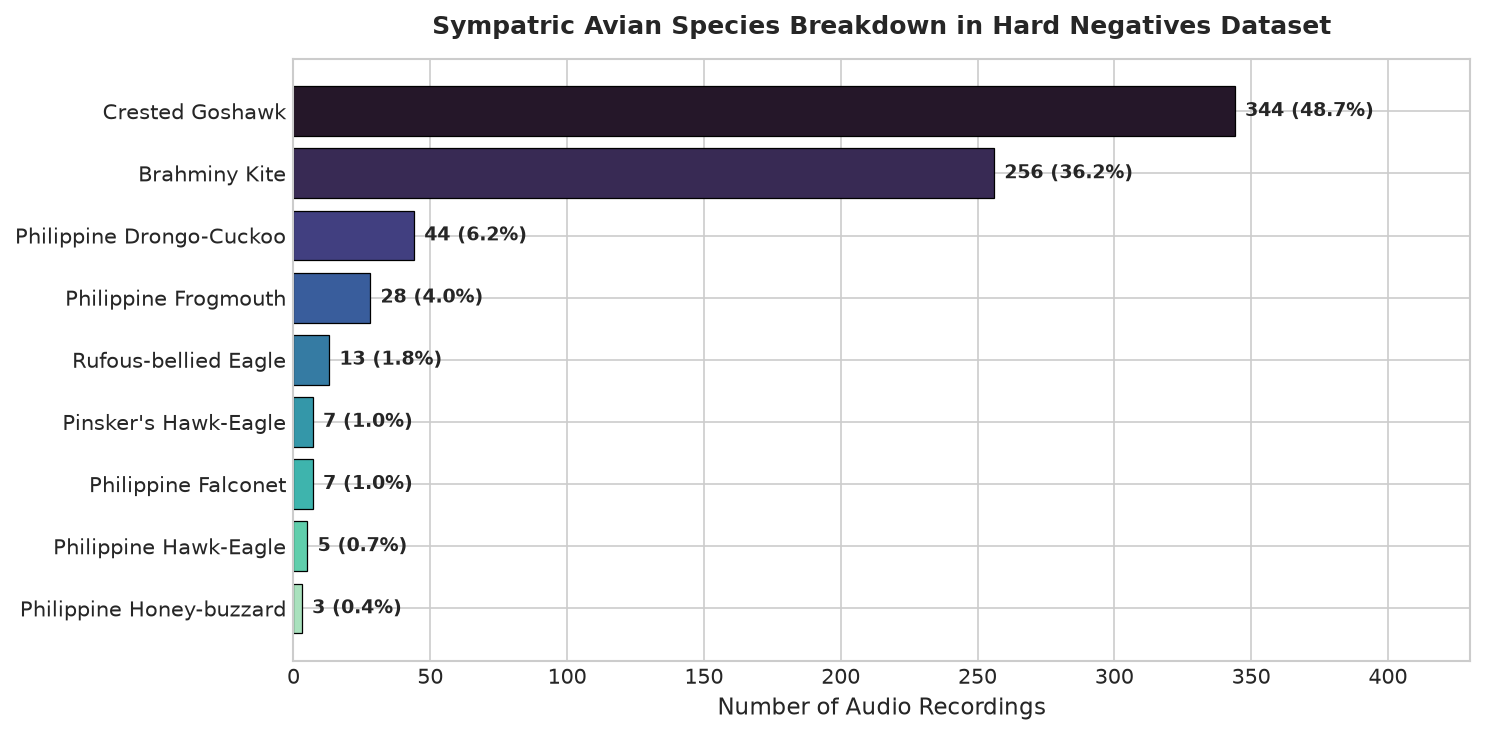

In [14]:
# Merge audio properties with catalog metadata
df_hard_neg_full = pd.merge(df_hard_neg_meta, df_hard_neg_audio_props, on="catalog_number", how="inner")

# Species distribution
species_counts = df_hard_neg_full["Common Name"].value_counts()
species_pcts = (species_counts / len(df_hard_neg_full) * 100).round(1)
df_species_summary = pd.DataFrame({"Count": species_counts, "Percentage (%)": species_pcts})

print("Sympatric Avian Species Distribution (Hard Negatives):")
print(df_species_summary.to_string())

# Plot species distribution
fig, ax = plt.subplots(figsize=(10, 5))
palette = sns.color_palette("mako", len(species_counts))
bars = ax.barh(species_counts.index[::-1], species_counts.values[::-1], color=palette[::-1], edgecolor="black", linewidth=0.6)

for bar in bars:
    width = bar.get_width()
    ax.annotate(f"{int(width)} ({width / len(df_hard_neg_full) * 100:.1f}%)",
                xy=(width, bar.get_y() + bar.get_height() / 2),
                xytext=(5, 0),
                textcoords="offset points",
                ha="left", va="center",
                fontweight="bold", fontsize=9)

ax.set_title("Sympatric Avian Species Breakdown in Hard Negatives Dataset", fontweight="bold", pad=12)
ax.set_xlabel("Number of Audio Recordings")
ax.set_xlim(0, max(species_counts) * 1.25)
plt.tight_layout()

output_path = FIGURES_DIR / "hard-negatives-species-distribution.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
print(f"Saved figure: {output_path}")
plt.show()


## 15. Visualize Hard Negatives Duration and Audio Format Distribution


Saved figures: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/01-dataset-exploration/outputs/figures/hard-negatives-duration-distribution.png and /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/01-dataset-exploration/outputs/figures/hard-negatives-format-distribution.png


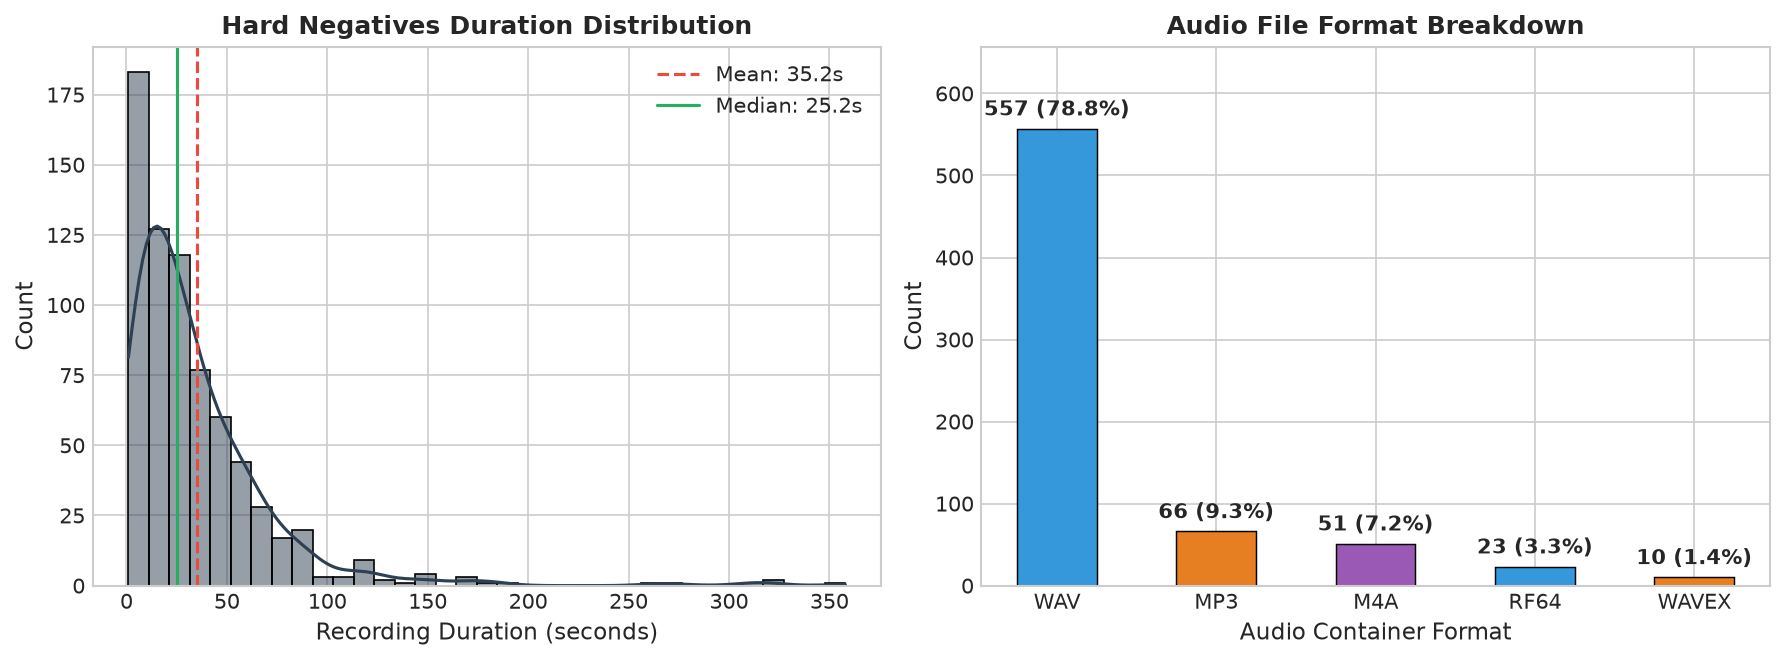

In [15]:
# Visualize duration and format distribution of hard negatives
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. Duration distribution (KDE + Histogram)
sns.histplot(df_hard_neg_full["duration_sec"], kde=True, color="#2e4053", bins=35, ax=ax1)
mean_dur = df_hard_neg_full["duration_sec"].mean()
median_dur = df_hard_neg_full["duration_sec"].median()
ax1.axvline(mean_dur, color="#e74c3c", linestyle="--", linewidth=1.5, label=f"Mean: {mean_dur:.1f}s")
ax1.axvline(median_dur, color="#27ae60", linestyle="-", linewidth=1.5, label=f"Median: {median_dur:.1f}s")
ax1.set_title("Hard Negatives Duration Distribution", fontweight="bold")
ax1.set_xlabel("Recording Duration (seconds)")
ax1.set_ylabel("Count")
ax1.legend()

# 2. Audio container formats
fmt_counts = df_hard_neg_full["format"].value_counts()
colors = ["#3498db", "#e67e22", "#9b59b6"]
bars = ax2.bar(fmt_counts.index, fmt_counts.values, color=colors[:len(fmt_counts)], edgecolor="black", linewidth=0.7, width=0.5)

for bar in bars:
    height = bar.get_height()
    ax2.annotate(f"{int(height)} ({height / len(df_hard_neg_full) * 100:.1f}%)",
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 4),
                 textcoords="offset points",
                 ha="center", va="bottom",
                 fontweight="bold")

ax2.set_title("Audio File Format Breakdown", fontweight="bold")
ax2.set_xlabel("Audio Container Format")
ax2.set_ylabel("Count")
ax2.set_ylim(0, max(fmt_counts) * 1.18)

plt.tight_layout()

# Save separate figures
out_dur = FIGURES_DIR / "hard-negatives-duration-distribution.png"
out_fmt = FIGURES_DIR / "hard-negatives-format-distribution.png"
fig.savefig(out_dur, dpi=300, bbox_inches="tight")
fig.savefig(out_fmt, dpi=300, bbox_inches="tight")
print(f"Saved figures: {out_dur} and {out_fmt}")
plt.show()


## 16. Analyze Geographic Distribution of Philippine Eagle Calls


PHILIPPINE EAGLE GEOGRAPHIC & RECORDING SITE BREAKDOWN
        Province ConfirmedCalls Recordings TotalDuration_s CallPercentage RecPercentage
        Cotabato          2,273         29        1,603.3s          59.4%         50.0%
   Davao del Sur          1,383         20        1,085.9s          36.2%         34.5%
        Bukidnon            115          6           89.7s           3.0%         10.3%
  Davao Oriental             50          1           28.6s           1.3%          1.7%
  Agusan del Sur              2          1            1.3s           0.1%          1.7%
Misamis Oriental              2          1            1.2s           0.1%          1.7%
Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/01-dataset-exploration/outputs/figures/eagle-geographic-distribution.png


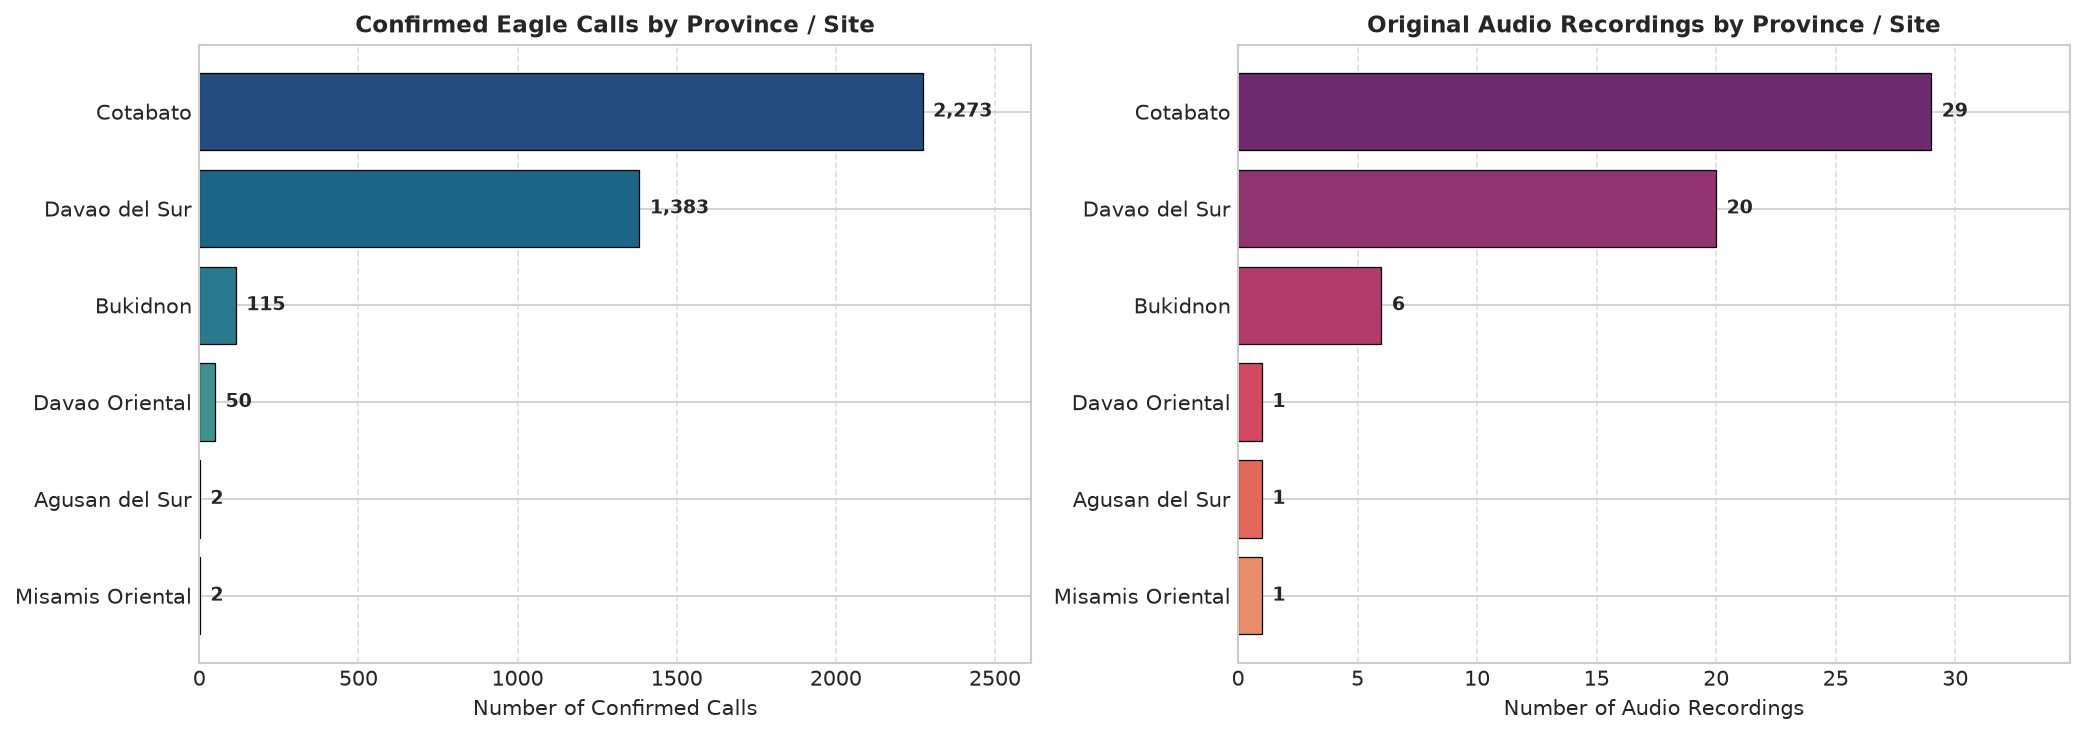

In [16]:
# Load raw metadata and map catalog numbers to recording provinces
if EAGLE_META_PATH.exists():
    df_eagle_meta = pd.read_csv(EAGLE_META_PATH)
    meta_dict = {str(row["ML Catalog Number"]).strip(): row["State"] for _, row in df_eagle_meta.iterrows()}
else:
    meta_dict = {}

# Map catalog number from AudioStem to State
df_eagle_geo = df_eagle.copy()
df_eagle_geo["CatalogNumber"] = df_eagle_geo["AudioStem"].apply(lambda s: re.search(r"\d+", str(s)).group() if re.search(r"\d+", str(s)) else "Unknown")
df_eagle_geo["Province"] = df_eagle_geo["CatalogNumber"].map(meta_dict).fillna("Unknown")

# Aggregate calls and unique recordings per province
province_summary = df_eagle_geo.groupby("Province").agg(
    ConfirmedCalls=("Duration (s)", "count"),
    Recordings=("CatalogNumber", "nunique"),
    TotalDuration_s=("Duration (s)", "sum")
).reset_index().sort_values("ConfirmedCalls", ascending=False)

province_summary["CallPercentage"] = (province_summary["ConfirmedCalls"] / province_summary["ConfirmedCalls"].sum()) * 100
province_summary["RecPercentage"] = (province_summary["Recordings"] / province_summary["Recordings"].sum()) * 100

print("=" * 75)
print("PHILIPPINE EAGLE GEOGRAPHIC & RECORDING SITE BREAKDOWN")
print("=" * 75)
print(province_summary.to_string(index=False, formatters={
    "ConfirmedCalls": lambda x: f"{x:,}",
    "Recordings": lambda x: f"{x:,}",
    "TotalDuration_s": lambda x: f"{x:,.1f}s",
    "CallPercentage": lambda x: f"{x:.1f}%",
    "RecPercentage": lambda x: f"{x:.1f}%"
}))
print("=" * 75)

# Dual-panel visualization: Calls and Field Recordings by Province
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Confirmed Calls
provinces = province_summary["Province"].values[::-1]
call_counts = province_summary["ConfirmedCalls"].values[::-1]
palette1 = sns.color_palette("crest", len(provinces))

bars1 = axes[0].barh(provinces, call_counts, color=palette1, edgecolor="black", linewidth=0.6)
axes[0].set_title("Confirmed Eagle Calls by Province / Site", fontweight="bold", fontsize=11)
axes[0].set_xlabel("Number of Confirmed Calls", fontsize=10)
axes[0].set_xlim(0, max(call_counts) * 1.15)
axes[0].grid(axis="x", linestyle="--", alpha=0.6)

for bar in bars1:
    w = bar.get_width()
    axes[0].annotate(f"{int(w):,}",
                     xy=(w, bar.get_y() + bar.get_height() / 2),
                     xytext=(5, 0), textcoords="offset points",
                     ha="left", va="center", fontweight="bold", fontsize=9)

# Panel 2: Field Recordings
rec_counts = province_summary["Recordings"].values[::-1]
palette2 = sns.color_palette("flare", len(provinces))

bars2 = axes[1].barh(provinces, rec_counts, color=palette2, edgecolor="black", linewidth=0.6)
axes[1].set_title("Original Audio Recordings by Province / Site", fontweight="bold", fontsize=11)
axes[1].set_xlabel("Number of Audio Recordings", fontsize=10)
axes[1].set_xlim(0, max(rec_counts) * 1.2)
axes[1].grid(axis="x", linestyle="--", alpha=0.6)

for bar in bars2:
    w = bar.get_width()
    axes[1].annotate(f"{int(w):,}",
                     xy=(w, bar.get_y() + bar.get_height() / 2),
                     xytext=(5, 0), textcoords="offset points",
                     ha="left", va="center", fontweight="bold", fontsize=9)

plt.tight_layout()
output_path = FIGURES_DIR / "eagle-geographic-distribution.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
print(f"Saved figure: {output_path}")
plt.show()


## 17. Analyze Geographic Distribution of Hard Negatives


Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/01-dataset-exploration/outputs/figures/hard-negatives-geographic-distribution.png


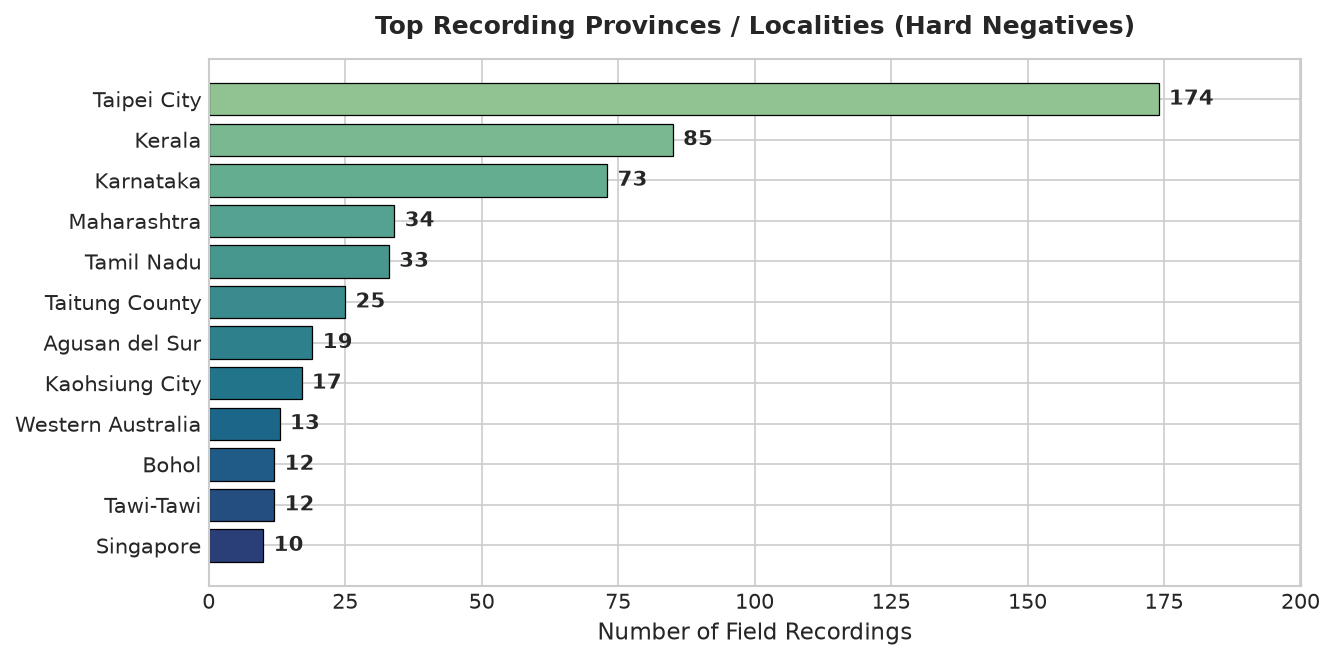

In [17]:
# Geographic distribution of hard negatives recordings across Philippine provinces
state_counts = df_hard_neg_full["State"].value_counts(dropna=False).head(12)

fig, ax = plt.subplots(figsize=(9, 4.5))
palette = sns.color_palette("crest", len(state_counts))
bars = ax.barh(state_counts.index[::-1], state_counts.values[::-1], color=palette[::-1], edgecolor="black", linewidth=0.6)

for bar in bars:
    width = bar.get_width()
    ax.annotate(f"{int(width)}",
                xy=(width, bar.get_y() + bar.get_height() / 2),
                xytext=(5, 0),
                textcoords="offset points",
                ha="left", va="center",
                fontweight="bold")

ax.set_title("Top Recording Provinces / Localities (Hard Negatives)", fontweight="bold", pad=12)
ax.set_xlabel("Number of Field Recordings")
ax.set_xlim(0, max(state_counts) * 1.15)
plt.tight_layout()

output_path = FIGURES_DIR / "hard-negatives-geographic-distribution.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
print(f"Saved figure: {output_path}")
plt.show()


## 18. Comparative Analysis: Philippine Eagle vs. Hard Negatives


                        Corpus  Recordings Count  Total Duration (Hours)  Mean Duration (s)        Target Class
0  Philippine Eagle (Positive)                59                    4.06              247.6  Positive (Class 1)
1    Hard Negatives (Negative)               707                    6.92               35.2  Negative (Class 0)
Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/01-dataset-exploration/outputs/figures/dataset-overview-comparison.png


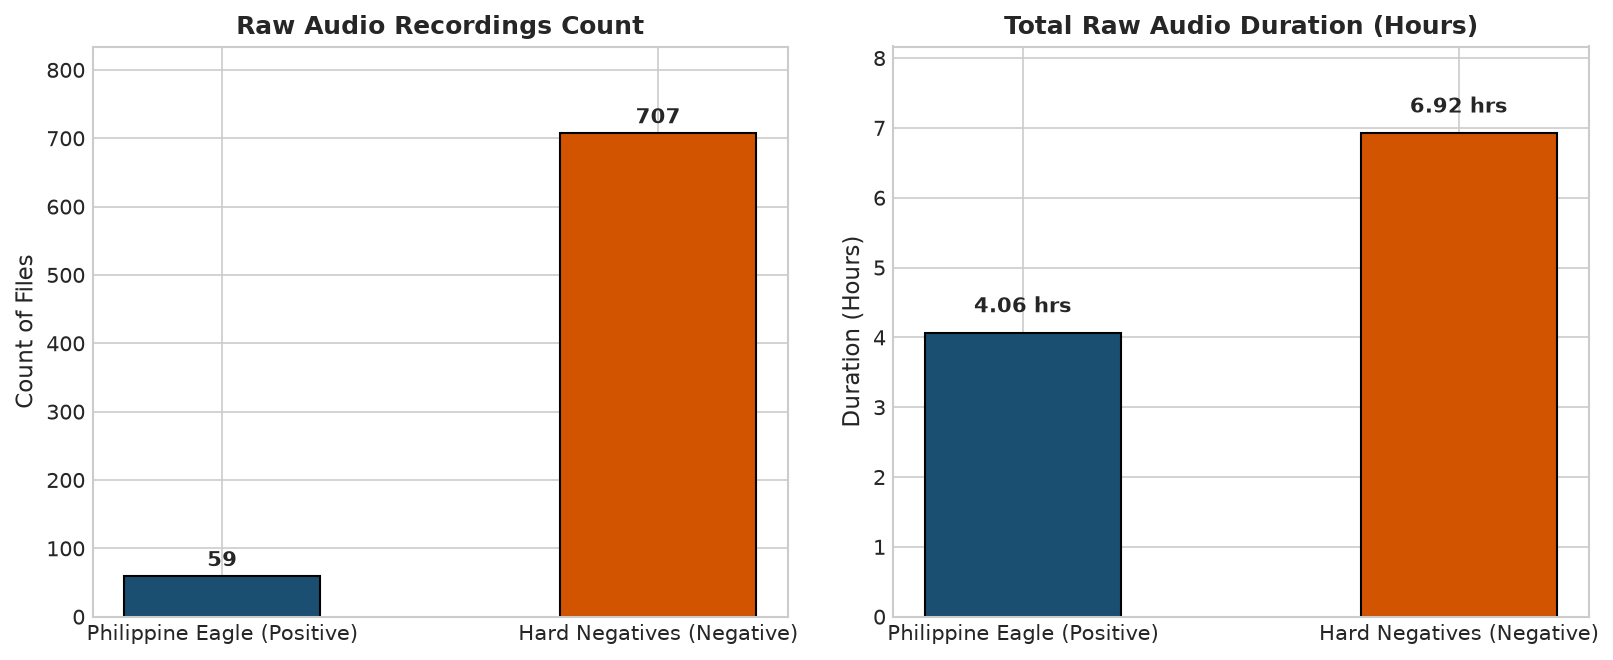

In [18]:
# Comparative analysis between Philippine Eagle and Hard Negatives corpora
eagle_total_hours = df_audio_props["Duration_s"].sum() / 3600
hard_neg_total_hours = df_hard_neg_audio_props["duration_sec"].sum() / 3600

comp_data = {
    "Corpus": ["Philippine Eagle (Positive)", "Hard Negatives (Negative)"],
    "Recordings Count": [len(df_audio_props), len(df_hard_neg_audio_props)],
    "Total Duration (Hours)": [round(eagle_total_hours, 2), round(hard_neg_total_hours, 2)],
    "Mean Duration (s)": [round(df_audio_props["Duration_s"].mean(), 1), round(df_hard_neg_audio_props["duration_sec"].mean(), 1)],
    "Target Class": ["Positive (Class 1)", "Negative (Class 0)"]
}
df_corpus_comp = pd.DataFrame(comp_data)
print(df_corpus_comp.to_string())

# Plot comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

# Total recordings count
ax1.bar(df_corpus_comp["Corpus"], df_corpus_comp["Recordings Count"], color=["#1b4f72", "#d35400"], edgecolor="black", width=0.45)
for i, v in enumerate(df_corpus_comp["Recordings Count"]):
    ax1.text(i, v + 15, f"{v:,}", ha="center", fontweight="bold")
ax1.set_title("Raw Audio Recordings Count", fontweight="bold")
ax1.set_ylabel("Count of Files")
ax1.set_ylim(0, max(df_corpus_comp["Recordings Count"]) * 1.18)

# Total audio hours
ax2.bar(df_corpus_comp["Corpus"], df_corpus_comp["Total Duration (Hours)"], color=["#1b4f72", "#d35400"], edgecolor="black", width=0.45)
for i, v in enumerate(df_corpus_comp["Total Duration (Hours)"]):
    ax2.text(i, v + 0.3, f"{v:.2f} hrs", ha="center", fontweight="bold")
ax2.set_title("Total Raw Audio Duration (Hours)", fontweight="bold")
ax2.set_ylabel("Duration (Hours)")
ax2.set_ylim(0, max(df_corpus_comp["Total Duration (Hours)"]) * 1.18)

plt.tight_layout()
output_path = FIGURES_DIR / "dataset-overview-comparison.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
print(f"Saved figure: {output_path}")
plt.show()


## 19. Consolidated Dataset Findings and Summary


In [19]:
# Consolidated summary of exploratory data analysis
summary_findings = {
    "Eagle Audio Recordings (Verified)": len(paired_stems),
    "Eagle Call Annotations (Confirmed)": len(df_eagle),
    "Eagle Raw Audio Duration (Hours)": round(df_audio_props["Duration_s"].sum() / 3600, 2),
    "Eagle Mean Call Duration (s)": round(df_eagle["Duration (s)"].mean(), 4),
    "Eagle Median Call Duration (s)": round(df_eagle["Duration (s)"].median(), 4),
    "Hard Negatives Recordings (100% Paired)": len(matched_hard_neg),
    "Hard Negatives Avian Species Count": df_hard_neg_full["Common Name"].nunique(),
    "Hard Negatives Total Duration (Hours)": round(df_hard_neg_audio_props["duration_sec"].sum() / 3600, 2),
    "Hard Negatives File Formats": df_hard_neg_full["format"].value_counts().to_dict(),
    "Total Combined Raw Audio (Hours)": round((df_audio_props["Duration_s"].sum() + df_hard_neg_audio_props["duration_sec"].sum()) / 3600, 2)
}

df_summary_report = pd.DataFrame(list(summary_findings.items()), columns=["Metric", "Value"])
print("Consolidated Dataset Exploration Report:")
print(df_summary_report.to_string())


Consolidated Dataset Exploration Report:
                                    Metric                                                        Value
0        Eagle Audio Recordings (Verified)                                                           59
1       Eagle Call Annotations (Confirmed)                                                         3825
2         Eagle Raw Audio Duration (Hours)                                                         4.06
3             Eagle Mean Call Duration (s)                                                       0.7346
4           Eagle Median Call Duration (s)                                                       0.7043
5  Hard Negatives Recordings (100% Paired)                                                          707
6       Hard Negatives Avian Species Count                                                            9
7    Hard Negatives Total Duration (Hours)                                                         6.92
8              Hard Neg